Homework 7

In [1]:
import os, zipfile, glob
if not os.path.exists("Frogs_MFCCs.csv"):
    z = glob.glob("/Users/sharvari/Downloads/Anuran Calls (MFCCs).zip")[0]
    zipfile.ZipFile(z).extractall(".")
print(os.path.exists("Frogs_MFCCs.csv"))

True


1. Multi-class and multi-label classification with SVMs

In [2]:
import json, os, pickle, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline as sk_make_pipeline
from sklearn.metrics import (confusion_matrix, precision_recall_fscore_support, roc_curve, auc,
                             roc_auc_score, multilabel_confusion_matrix)
from sklearn.preprocessing import label_binarize
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import make_pipeline as imb_make_pipeline

warnings.filterwarnings("ignore")
SEED = 0
OUT, FIG = "results", "figures"
os.makedirs("ckpt", exist_ok=True); os.makedirs(OUT, exist_ok=True); os.makedirs(FIG, exist_ok=True)
LABELS = ["Family", "Genus", "Species"]
log_lines = []
def log(*a):
    s = " ".join(str(x) for x in a); print(s, flush=True); log_lines.append(s)

1(a) Data and 70% random training set

In [3]:
df = pd.read_csv("Frogs_MFCCs.csv")
feat = [c for c in df.columns if c.startswith("MFCCs")]         
X = df[feat].values
Y = df[LABELS].values
Xtr, Xte, Ytr, Yte = train_test_split(X, Y, train_size=0.7, random_state=SEED, shuffle=True)
log(f"train={len(Xtr)}  test={len(Xte)}  (70% / 30% random split, seed={SEED})")
scaler = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

train=5036  test=2159  (70% / 30% random split, seed=0)


1(b)i Evaluation measures: exact match, Hamming score / loss

In [4]:
def multilabel_metrics(Ytrue, Ypred):
    wrong = (Ytrue != Ypred)
    n, L = Ytrue.shape
    out = dict(exact_match=float(np.mean(~wrong.any(1))),
               hamming_score=float(1 - wrong.mean()),
               hamming_loss=float(wrong.mean()),
               hamming_distance=float(wrong.sum(1).mean()))
    jac = []
    for t, p in zip(Ytrue, Ypred):
        a, b = set(t), set(p); jac.append(len(a & b) / len(a | b))
    out["set_based_score"] = float(np.mean(jac))
    for j, l in enumerate(LABELS): out[f"acc_{l}"] = float(1 - wrong[:, j].mean())
    return out

results = [] 
def record(name, Ptr, Pte):
    for split, T, P in (("train", Ytr, Ptr), ("test", Yte, Pte)):
        m = multilabel_metrics(T, P); m.update(classifier=name, split=split); results.append(m)
    mt = results[-1]
    log(f"   {name:38s} TEST exact={mt['exact_match']:.4f} hamming_score={mt['hamming_score']:.4f} "
        f"hamming_loss={mt['hamming_loss']:.4f}  | acc F/G/S = {mt['acc_Family']:.3f}/{mt['acc_Genus']:.3f}/{mt['acc_Species']:.3f}")

1(b)ii Gaussian-kernel one-vs-all SVMs

In [5]:
def sigma2gamma(s): return 1.0 / (2.0 * s ** 2)

def find_ranges(Xa, ya, thr=0.70):
    sig_cand = np.array([0.02, 0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50])
    ok_s = []
    for s in sig_cand:
        m = OneVsRestClassifier(SVC(kernel="rbf", C=10, gamma=sigma2gamma(s))).fit(Xa, ya)
        if m.score(Xa, ya) >= thr: ok_s.append(s)
    s_ref = float(np.median(ok_s)) if ok_s else 1.0
    C_exp = np.arange(-3, 7)
    ok_c = []
    for e in C_exp:
        m = OneVsRestClassifier(SVC(kernel="rbf", C=10.0 ** e, gamma=sigma2gamma(s_ref))).fit(Xa, ya)
        if m.score(Xa, ya) >= thr: ok_c.append(e)
    return ok_s, ok_c

NC, NS = 6, 6          
gauss_models, gauss_best = {}, {}
for prep, (A, B) in {"standardized": (Xtr_s, Xte_s), "raw": (Xtr, Xte)}.items():
    log(f"\n1(b)ii Gaussian-kernel SVM (one-vs-all), {prep} attributes")
    Ptr, Pte = [], []
    for j, lab in enumerate(LABELS):
        t0 = time.time()
        sigmas = np.linspace(2, 5, 4) if prep == "standardized" else np.linspace(0.1, 0.5, 5)    
        Cs = 10.0 ** np.arange(0, 4) if prep == "standardized" else 10.0 ** np.arange(0, 5)     
        log(f"  [{lab}] sigma grid: {np.round(sigmas, 3).tolist()}  log10(C) grid: {np.log10(Cs).tolist()}")
        grid = {"estimator__C": Cs, "estimator__gamma": [sigma2gamma(s) for s in sigmas]}
        ck = f"ckpt/gauss_{prep}_{lab}.pkl"
        if os.path.exists(ck): gs = pickle.load(open(ck, "rb"))
        else:
            gs = GridSearchCV(OneVsRestClassifier(SVC(kernel="rbf")), grid, cv=cv, scoring="accuracy",
                              n_jobs=1, refit=True).fit(A, Ytr[:, j])
            pickle.dump(gs, open(ck, "wb"))
        g = gs.best_params_["estimator__gamma"]; sig = float(np.sqrt(1 / (2 * g)))
        gauss_models[(prep, lab)] = gs.best_estimator_
        gauss_best[(prep, lab)] = dict(C=float(gs.best_params_["estimator__C"]), sigma=sig, gamma=float(g),
                                       cv_acc=float(gs.best_score_))
        log(f"  [{lab}] best C={gauss_best[(prep, lab)]['C']:.4g} sigma={sig:.4g}  10-fold CV acc={gs.best_score_:.4f}"
            f"  ({time.time() - t0:.0f}s)")
        Ptr.append(gs.predict(A)); Pte.append(gs.predict(B))
    record(f"Gaussian SVM OvA ({prep})", np.column_stack(Ptr), np.column_stack(Pte))


1(b)ii Gaussian-kernel SVM (one-vs-all), standardized attributes
  [Family] sigma grid: [2.0, 3.0, 4.0, 5.0]  log10(C) grid: [0.0, 1.0, 2.0, 3.0]
  [Family] best C=100 sigma=4  10-fold CV acc=0.9921  (0s)
  [Genus] sigma grid: [2.0, 3.0, 4.0, 5.0]  log10(C) grid: [0.0, 1.0, 2.0, 3.0]
  [Genus] best C=10 sigma=3  10-fold CV acc=0.9901  (0s)
  [Species] sigma grid: [2.0, 3.0, 4.0, 5.0]  log10(C) grid: [0.0, 1.0, 2.0, 3.0]
  [Species] best C=10 sigma=4  10-fold CV acc=0.9883  (0s)
   Gaussian SVM OvA (standardized)        TEST exact=0.9875 hamming_score=0.9915 hamming_loss=0.0085  | acc F/G/S = 0.994/0.990/0.991

1(b)ii Gaussian-kernel SVM (one-vs-all), raw attributes
  [Family] sigma grid: [0.1, 0.2, 0.3, 0.4, 0.5]  log10(C) grid: [0.0, 1.0, 2.0, 3.0, 4.0]
  [Family] best C=100 sigma=0.4  10-fold CV acc=0.9931  (0s)
  [Genus] sigma grid: [0.1, 0.2, 0.3, 0.4, 0.5]  log10(C) grid: [0.0, 1.0, 2.0, 3.0, 4.0]
  [Genus] best C=100 sigma=0.3  10-fold CV acc=0.9907  (0s)
  [Species] sigma grid:

1(b)iii L1-penalised SVMs standardized, C by 10fold CV

In [6]:
log("\nL1-penalised linear SVMs (one-vs-all), standardized attributes")
Cgrid = 10.0 ** np.arange(-3, 4.01, 0.5)
l1_models, l1_best = {}, {}
Ptr, Pte = [], []
for j, lab in enumerate(LABELS):
    ck = f"ckpt/l1_{lab}.pkl"
    if os.path.exists(ck): gs = pickle.load(open(ck, "rb"))
    else:
        gs = GridSearchCV(OneVsRestClassifier(LinearSVC(penalty="l1", dual=False, max_iter=20000)),
                          {"estimator__C": Cgrid}, cv=cv, scoring="accuracy", n_jobs=1).fit(Xtr_s, Ytr[:, j])
        pickle.dump(gs, open(ck, "wb"))
    l1_models[lab] = gs.best_estimator_
    l1_best[lab] = dict(C=float(gs.best_params_["estimator__C"]), cv_acc=float(gs.best_score_))
    log(f"  [{lab}] best C={l1_best[lab]['C']:.4g}  10-fold CV acc={gs.best_score_:.4f}")
    Ptr.append(gs.predict(Xtr_s)); Pte.append(gs.predict(Xte_s))
record("L1-SVM (standardized)", np.column_stack(Ptr), np.column_stack(Pte))


L1-penalised linear SVMs (one-vs-all), standardized attributes
  [Family] best C=1  10-fold CV acc=0.9377
  [Genus] best C=10  10-fold CV acc=0.9519
  [Species] best C=3.162  10-fold CV acc=0.9609
   L1-SVM (standardized)                  TEST exact=0.9138 hamming_score=0.9463 hamming_loss=0.0537  | acc F/G/S = 0.934/0.948/0.957


1(b)iv L1-penalised SVMs and SMOTE

In [7]:
log("\nL1-penalised SVMs + SMOTE, standardized attributes")
smote_models, smote_best = {}, {}
Ptr, Pte = [], []
for j, lab in enumerate(LABELS):
    pipe = imb_make_pipeline(SMOTE(random_state=SEED, k_neighbors=5),
                             OneVsRestClassifier(LinearSVC(penalty="l1", dual=False, max_iter=20000)))
    key = [k for k in pipe.get_params() if k.endswith("estimator__C")][0]
    ck = f"ckpt/smote_{lab}.pkl"
    if os.path.exists(ck): gs = pickle.load(open(ck, "rb"))
    else:
        gs = GridSearchCV(pipe, {key: 10.0 ** np.arange(-1, 2.01, 1.0)}, cv=cv, scoring="accuracy", n_jobs=1).fit(Xtr_s, Ytr[:, j])
        pickle.dump(gs, open(ck, "wb"))
    smote_models[lab] = gs.best_estimator_
    smote_best[lab] = dict(C=float(gs.best_params_[key]), cv_acc=float(gs.best_score_))
    log(f"  [{lab}] best C={smote_best[lab]['C']:.4g}  10-fold CV acc={gs.best_score_:.4f}")
    Ptr.append(gs.predict(Xtr_s)); Pte.append(gs.predict(Xte_s))
record("L1-SVM + SMOTE (standardized)", np.column_stack(Ptr), np.column_stack(Pte))


L1-penalised SVMs + SMOTE, standardized attributes
  [Family] best C=10  10-fold CV acc=0.9245
  [Genus] best C=1  10-fold CV acc=0.9241
  [Species] best C=0.1  10-fold CV acc=0.9565
   L1-SVM + SMOTE (standardized)          TEST exact=0.8560 hamming_score=0.9230 hamming_loss=0.0770  | acc F/G/S = 0.912/0.903/0.953


2. K-means clustering on the multi-label data set 50 Monte-Carlo runs

(a) k ∈ {1,…,50} chosen by silhouette, (b) majority family/genus/species per cluster and (c) Hamming distance, score, loss.

run  1: k= 5 silhouette=0.3700  Hamming distance=0.5976 score=0.8008 loss=0.1992  [105s]
run  2: k= 4 silhouette=0.3840  Hamming distance=0.7009 score=0.7664 loss=0.2336  [129s]
run  3: k= 4 silhouette=0.3853  Hamming distance=0.7354 score=0.7549 loss=0.2451  [264s]
run  4: k= 4 silhouette=0.3779  Hamming distance=0.5591 score=0.8136 loss=0.1864  [295s]
run  5: k= 4 silhouette=0.3787  Hamming distance=0.6664 score=0.7779 loss=0.2221  [327s]
run  6: k= 5 silhouette=0.3717  Hamming distance=0.5033 score=0.8322 loss=0.1678  [520s]
run  7: k= 4 silhouette=0.3840  Hamming distance=0.7012 score=0.7663 loss=0.2337  [534s]
run  8: k= 4 silhouette=0.3788  Hamming distance=0.6673 score=0.7776 loss=0.2224  [548s]
run  9: k= 6 silhouette=0.3800  Hamming distance=0.5640 score=0.8120 loss=0.1880  [562s]
run 10: k= 4 silhouette=0.3853  Hamming distance=0.7354 score=0.7549 loss=0.2451  [576s]
run 11: k= 4 silhouette=0.3788  Hamming distance=0.6673 score=0.7776 loss=0.2224  [590s]
run 12: k= 4 silhouet

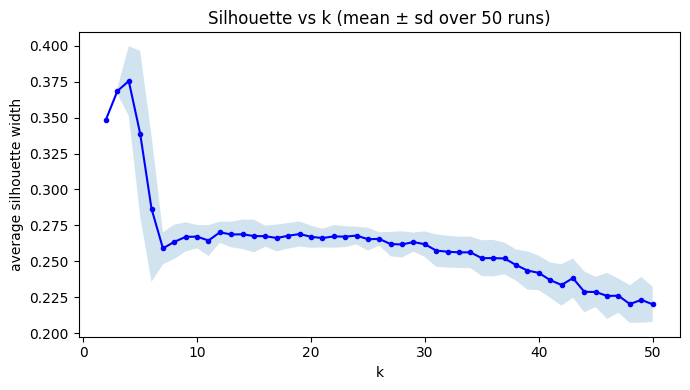

In [8]:
import os, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, pairwise_distances

OUT, FIG = "results", "figures"
os.makedirs(OUT, exist_ok=True); os.makedirs(FIG, exist_ok=True)
LABELS = ["Family", "Genus", "Species"]
df = pd.read_csv("Frogs_MFCCs.csv")
X = df[[c for c in df.columns if c.startswith("MFCCs")]].values
Y = df[LABELS].values
n = len(X)
D = pairwise_distances(X).astype(np.float32)       

N_RUNS, K_MAX = 50, 50
rows, sil_curves, log = [], [], []
t0 = time.time()
for run in range(N_RUNS):
    sil = {}
    models = {}
    for k in range(2, K_MAX + 1):
        km = KMeans(n_clusters=k, n_init=3, random_state=1000 * run + k).fit(X)
        models[k] = km.labels_
        sil[k] = silhouette_score(D, km.labels_, metric="precomputed")
    k_best = max(sil, key=sil.get); lab = models[k_best]
    sil_curves.append([sil[k] for k in range(2, K_MAX + 1)])

    maj = {}
    for c in range(k_best):
        idx = np.where(lab == c)[0]
        maj[c] = tuple(pd.Series(Y[idx, j]).value_counts().index[0] for j in range(3))
    pred = np.array([maj[c] for c in lab])

    wrong = (Y != pred)
    dist = wrong.sum(1).mean()               
    loss = wrong.mean()                        
    score = 1 - loss
    rows.append(dict(run=run + 1, k=k_best, silhouette=sil[k_best], hamming_distance=dist, hamming_score=score,
                     hamming_loss=loss, acc_Family=1 - wrong[:, 0].mean(), acc_Genus=1 - wrong[:, 1].mean(),
                     acc_Species=1 - wrong[:, 2].mean()))
    msg = (f"run {run + 1:2d}: k={k_best:2d} silhouette={sil[k_best]:.4f}  Hamming distance={dist:.4f} "
           f"score={score:.4f} loss={loss:.4f}  [{time.time() - t0:.0f}s]")
    print(msg, flush=True); log.append(msg)

R = pd.DataFrame(rows); R.to_csv(f"{OUT}/q2_monte_carlo_runs.csv", index=False)
summ = pd.DataFrame({"mean": R[["hamming_distance", "hamming_score", "hamming_loss", "k"]].mean(),
                     "std": R[["hamming_distance", "hamming_score", "hamming_loss", "k"]].std(ddof=1)})
summ.to_csv(f"{OUT}/q2_summary.csv")
s = "\nQ2 summary over 50 Monte-Carlo runs std = sample std, ddof=1\n" + summ.round(4).to_string()
s += "\n\nchosen k per run counts:\n" + R["k"].value_counts().sort_index().to_string()
s += "\n\nper-label accuracy of cluster-majority labels (mean over runs):\n" + R[["acc_Family", "acc_Genus", "acc_Species"]].mean().round(4).to_string()
print(s); open(f"{OUT}/q2_log.txt", "w").write("\n".join(log) + "\n" + s)

SC = np.array(sil_curves)
plt.figure(figsize=(7, 4))
plt.plot(range(2, K_MAX + 1), SC.mean(0), "b-o", ms=3); plt.fill_between(range(2, K_MAX + 1), SC.mean(0) - SC.std(0), SC.mean(0) + SC.std(0), alpha=.2)
plt.xlabel("k"); plt.ylabel("average silhouette width"); plt.title("Silhouette vs k (mean ± sd over 50 runs)")
plt.tight_layout(); plt.savefig(f"{FIG}/q2_silhouette_vs_k.png", dpi=120); plt.show()

3. ISLR 12.6.2

(a) complete linkage
   fusion 1: [1] + [2] -> [1, 2] at height 0.30
   fusion 2: [3] + [4] -> [3, 4] at height 0.45
   fusion 3: [1, 2] + [3, 4] -> [1, 2, 3, 4] at height 0.80
(b) single linkage
   fusion 1: [1] + [2] -> [1, 2] at height 0.30
   fusion 2: [3] + [1, 2] -> [1, 2, 3] at height 0.40
   fusion 3: [4] + [1, 2, 3] -> [1, 2, 3, 4] at height 0.45
(c) cutting the complete-linkage dendrogram into two clusters: [1, 2]  and  [3, 4]
(d) cutting the single-linkage dendrogram into two clusters: [1, 2, 3]  and  [4]
(e) leaf order 4,3,2,1 (swapping the branches at the root fusion and at the two lower fusions) gives the same tree: {1,2} fuse at 0.30, {3,4} at 0.45, everything at 0.80.


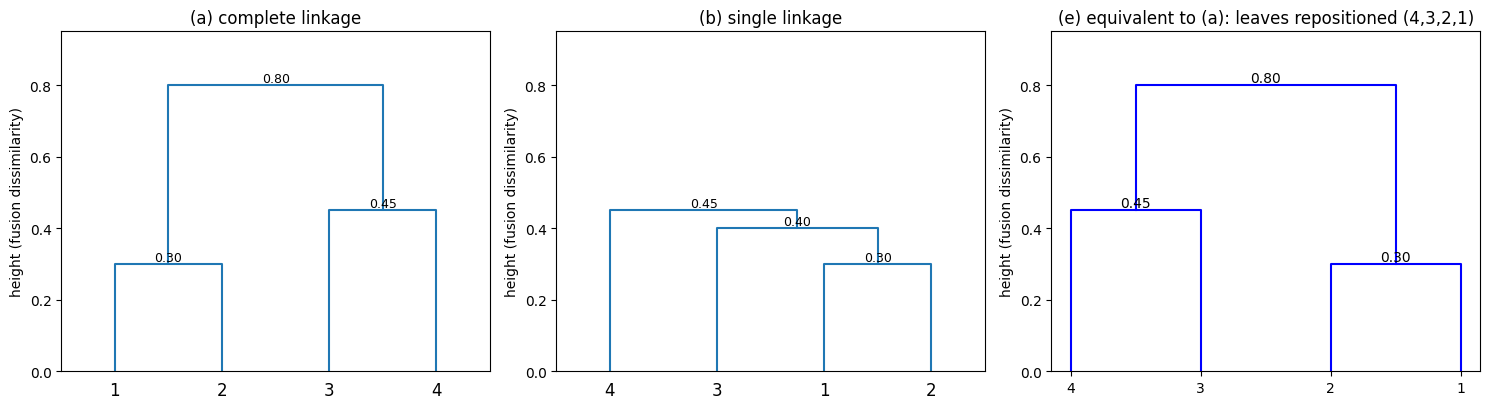

692

In [9]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform

os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
Dm = np.array([[0, .3, .4, .7], [.3, 0, .5, .8], [.4, .5, 0, .45], [.7, .8, .45, 0]])
d = squareform(Dm)
out = []
def P(s=""): print(s); out.append(s)

def merges(Z):
    members = {i: [i + 1] for i in range(4)}
    res = []
    for i, (a, b, h, _) in enumerate(Z):
        m = sorted(members[int(a)] + members[int(b)]); members[4 + i] = m
        res.append((m, h)); P(f"   fusion {i + 1}: {members[int(a)]} + {members[int(b)]} -> {m} at height {h:.2f}")
    return res

fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
sol = {}
for ax, (method, tag) in zip(axs[:2], (("complete", "(a) complete linkage"), ("single", "(b) single linkage"))):
    Z = linkage(d, method=method); sol[method] = Z
    P(f"{tag}"); merges(Z)
    dn = dendrogram(Z, labels=["1", "2", "3", "4"], ax=ax, color_threshold=0)
    for ic, dc in zip(dn["icoord"], dn["dcoord"]):
        ax.annotate(f"{dc[1]:.2f}", (0.5 * (ic[1] + ic[2]), dc[1]), va="bottom", ha="center", fontsize=9)
    ax.set_title(tag); ax.set_ylabel("height (fusion dissimilarity)"); ax.set_ylim(0, 0.95)

for method, tag in (("complete", "(c)"), ("single", "(d)")):
    cl = fcluster(sol[method], t=2, criterion="maxclust")
    groups = {c: [int(i) + 1 for i in np.where(cl == c)[0]] for c in sorted(set(cl))}
    P(f"{tag} cutting the {method}-linkage dendrogram into two clusters: " + "  and  ".join(str(g) for g in groups.values()))

ax = axs[2]
pos = {4: 0, 3: 1, 2: 2, 1: 3}                     
def seg(x1, x2, h1, h2, h):
    ax.plot([x1, x1, x2, x2], [h1, h, h, h2], "b-")
x34 = (pos[4] + pos[3]) / 2; x12 = (pos[2] + pos[1]) / 2
seg(pos[4], pos[3], 0, 0, .45); ax.text(x34, .45, "0.45", ha="center", va="bottom")
seg(pos[2], pos[1], 0, 0, .30); ax.text(x12, .30, "0.30", ha="center", va="bottom")
seg(x34, x12, .45, .30, .80); ax.text((x34 + x12) / 2, .80, "0.80", ha="center", va="bottom")
ax.set_xticks(list(pos.values())); ax.set_xticklabels([str(k) for k in pos.keys()])
ax.set_title("(e) equivalent to (a): leaves repositioned (4,3,2,1)"); ax.set_ylim(0, .95); ax.set_ylabel("height (fusion dissimilarity)")
P("(e) leaf order 4,3,2,1 (swapping the branches at the root fusion and at the two lower fusions) gives the same "
  "tree: {1,2} fuse at 0.30, {3,4} at 0.45, everything at 0.80.")
plt.tight_layout(); plt.savefig("figures/q3_dendrograms.png", dpi=130); plt.show()
open("results/q3_log.txt", "w").write("\n".join(out))